In [2]:
%pip install shapiq
%pip install shapiq scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import shapiq

print("shapiq-Version:", shapiq.__version__)

shapiq-Version: 1.8.0


numpy für Arrays 
matplotlib für Zeichnen
sklearn für two_moons
shapiq

In [4]:
def preisgeld(koalitionen):
    ergebnisse = []
    for anna, ben, cem in koalitionen:          # jede Zeile = eine Gruppe
        geld = 10 * anna + 20 * ben + 0 * cem
        if anna and ben:
            geld += 50                          # Team-Bonus
        ergebnisse.append(geld)
    return np.array(ergebnisse, dtype=float)

# Test: niemand / nur Anna / Anna+Ben / alle
test = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [1, 1, 1]], dtype=bool)
print(preisgeld(test))      # [0, 10, 80, 80]

[ 0. 10. 80. 80.]



Drei Spieler: **Anna (0)**, **Ben (1)**, **Cem (2)**. Die Regeln für das Preisgeld:
- Anna bringt allein **10 €**
- Ben bringt allein **20 €**
- Cem bringt **nichts**
- Wenn **Anna und Ben zusammen** spielen, gibt es **50 € Bonus** (sie sind ein gutes Team)

Für shapiq schreiben wir das als **Funktion**. Sie bekommt eine Tabelle von „Gruppen“ (*Koalitionen*):
jede Zeile ist eine Gruppe, jede Spalte ein Spieler, `True` = spielt mit. Sie gibt für jede Gruppe das Preisgeld zurück.

In [5]:
rechner = shapiq.ExactComputer(game=preisgeld, n_players=3)

sv = rechner(index="SV", order=1)
print(sv)

InteractionValues(
    index=SV, max_order=1, min_order=0, estimated=False, estimation_budget=None,
    n_players=3, baseline_value=0.0,
    Top 10 interactions:
        (1,): 45.0
        (0,): 35.0
        (): 0.0
        (2,): 0.0
)


`shapiq.ExactComputer` probiert **alle** möglichen Gruppen durch (bei 3 Spielern sind das 2³ = 8) und rechnet exakt.
- `index="SV"` = normale **Shapley-Werte** (jeder Spieler bekommt einen Anteil)
- `order=1` = nur einzelne Spieler betrachten

- `(0,)` = Anna, `(1,)` = Ben, `(2,)` = Cem, `()` = Basiswert (Preisgeld, wenn niemand spielt = 0)
- Anna bekommt **35 €** = ihre 10 € + **die Hälfte** des Bonus (25 €)
- Ben bekommt **45 €** = seine 20 € + die andere Hälfte des Bonus
- Cem bekommt **0 €** – er trägt nichts bei
- Summe: 0 + 35 + 45 + 0 = **80 €** = Preisgeld, wenn alle spielen ✓

------------------------------------------------------------------------------------------------------------------------------------------------------------

X: (500, 2)   y: (500,)


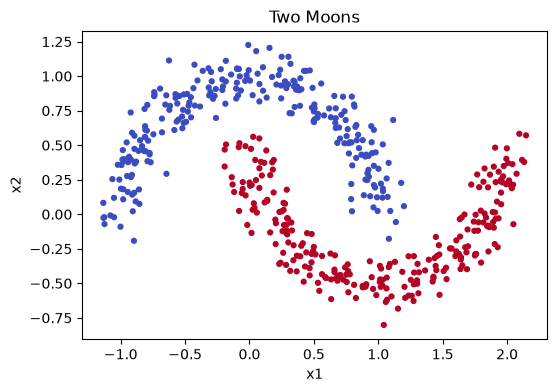

In [15]:
X, y = make_moons(n_samples=500, noise=0.1, random_state=0)
MERKMALE = ["x1", "x2"]

print("X:", X.shape, "  y:", y.shape)
plt.figure(figsize=(6, 4))
plt.scatter(*X.T, c=y, cmap="coolwarm", s=12)
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("Two Moons"); plt.show()

In [17]:
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

X_test, y_test = make_moons(n_samples=300, noise=0.2, random_state=1)

mlp = MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=1000, random_state=0).fit(X, y)
rf  = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=0).fit(X, y)

print(f"Netz (MLP)    Test-Genauigkeit: {mlp.score(X_test, y_test):.3f}")
print(f"Random Forest Test-Genauigkeit: {rf.score(X_test, y_test):.3f}")

Netz (MLP)    Test-Genauigkeit: 0.977
Random Forest Test-Genauigkeit: 0.957


Wir trainieren **zwei verschiedene Modelle** mit scikit-learn (beide liefern Wahrscheinlichkeiten über `predict_proba`):
- **MLPClassifier** – ein neuronales Netz mit zwei Schichten à 64 Neuronen
- **RandomForestClassifier** – 100 Entscheidungsbäume, die abstimmen

`fit(X, y)` trainiert, `score` gibt die Genauigkeit zurück.

**RandomForestClassifier: viele Bäume stimmen ab**

Ein einzelner Entscheidungsbaum ist eine Kette von Ja/Nein-Fragen, wie beim Spiel „Wer bin ich?“:

Ist x2 > 0.3?
├── ja  → Ist x1 < 1.2?
│         ├── ja  → blau
│         └── nein → rot
└── nein → rot

Ein Random Forest besteht aus vielen solchen Bäumen (z. B. 100). Jeder Baum lernt mit einer etwas anderen, zufälligen Auswahl der Daten. Am Ende stimmen alle ab: Sagen 66 von 100 Bäumen „rot“, ist P(rot) = 0.66.


n_estimators=100 -> Anzahl Bäume 
max_depth=6  -> max. Anzahl Fragen hintereinander 


**MLPClassifier: ein neuronales Netz**

MLP steht für Multi-Layer Perceptron und ist dasselbe wie dein PyTorch-Netz: Schichten aus Neuronen, die gewichtete Summen bilden, dazu ReLU. Es lernt, indem es die Gewichte Schritt für Schritt anpasst.

(64,64) -> zwe Neuronale Netze mit je 64 Neutronen
max_Iter = max.Trainingsdurchläufe

In [19]:
punkte = {
    "A: im blauen Mond":  np.array([-0.8, 0.6]),
    "B: an der Grenze":   np.array([0.5, 0.25]),
    "C: im roten Mond":   np.array([1.5, -0.4]),
}
for name, p in punkte.items():
    print(f"{name:20s} P(rot) Netz = {mlp.predict_proba([p])[0, 1]:.3f}   Forest = {rf.predict_proba([p])[0, 1]:.3f}")


A: im blauen Mond    P(rot) Netz = 0.000   Forest = 0.000
B: an der Grenze     P(rot) Netz = 0.462   Forest = 0.660
C: im roten Mond     P(rot) Netz = 0.999   Forest = 1.000


----------------------------------------------------------------------

Summenregel Random Forest: True
Summenregel Netz (MLP):    True
Random Forest  Ø|x1| = 0.223   Ø|x2| = 0.263   Ø|x1×x2| = 0.158
Netz (MLP)     Ø|x1| = 0.238   Ø|x2| = 0.258   Ø|x1×x2| = 0.171


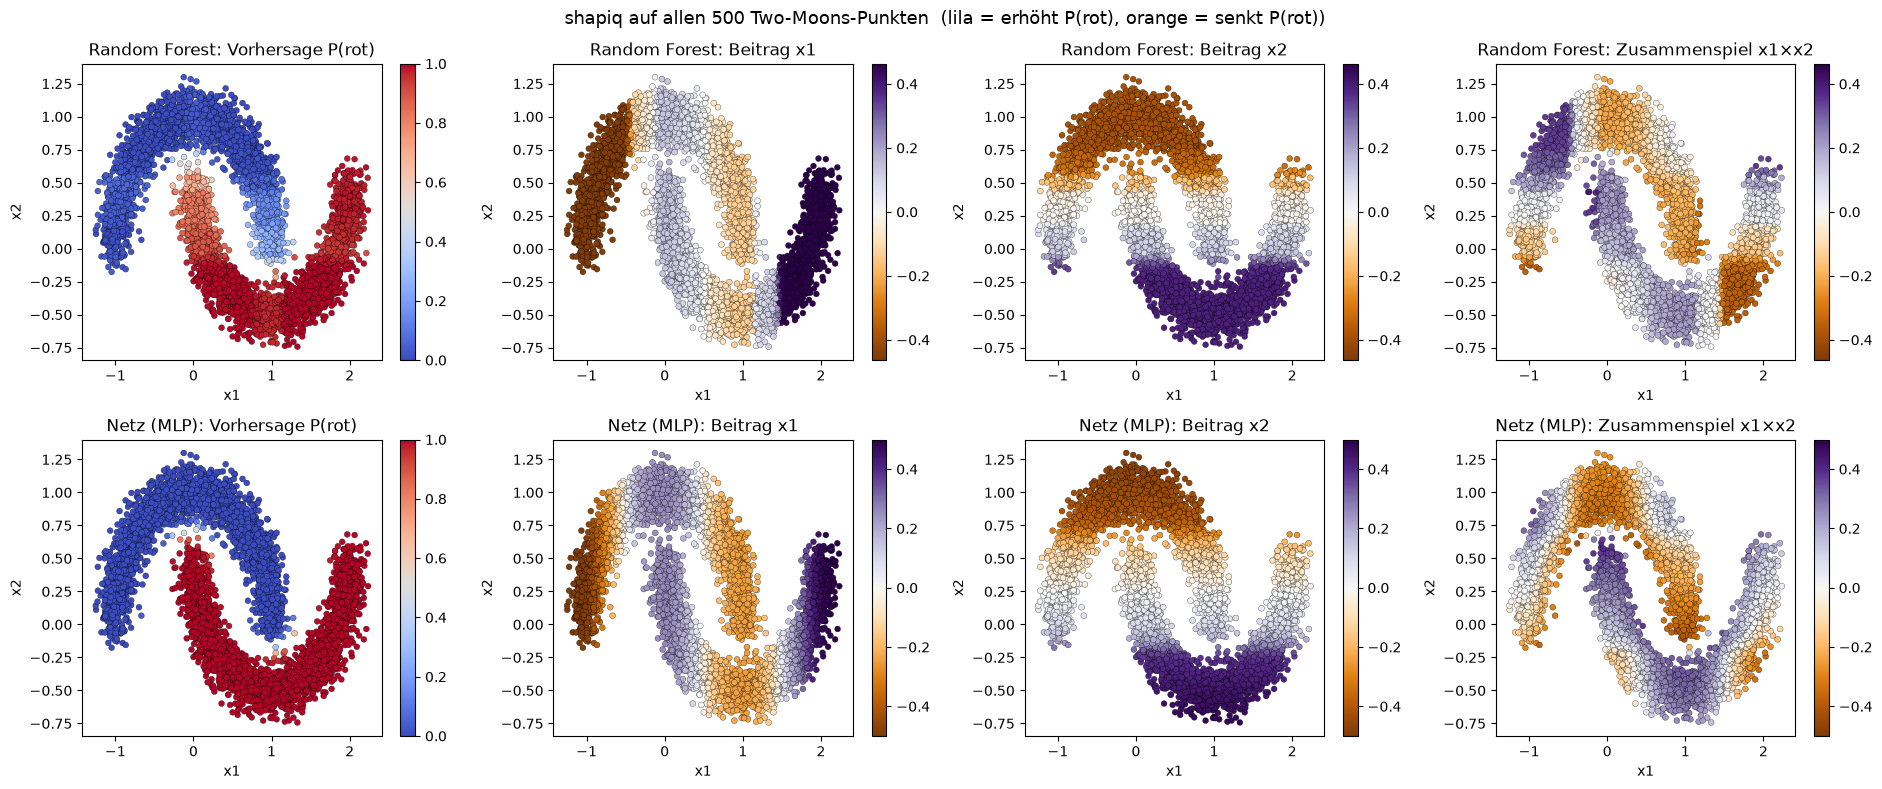

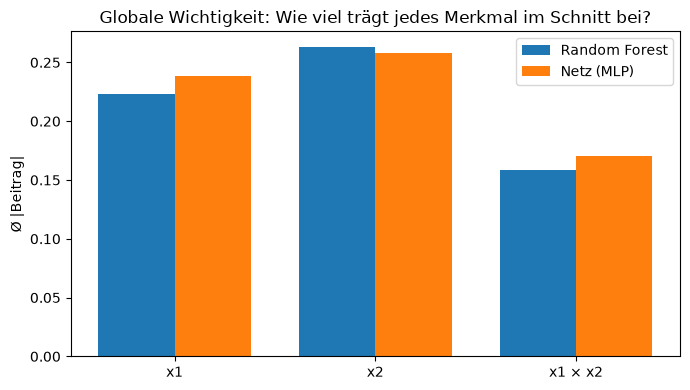

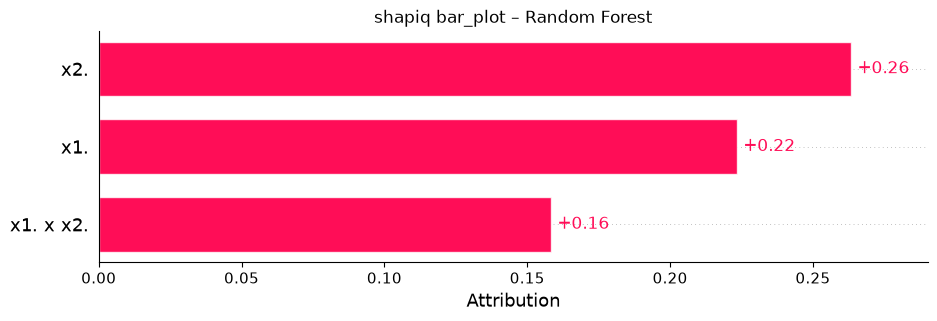

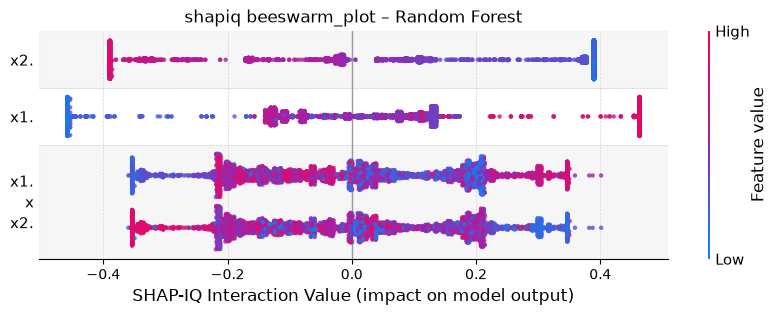

In [24]:
# =====================================================================
# Two Moons komplett mit shapiq erklären – alle 500 Punkte auf einmal
# =====================================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import shapiq

# ---------------------------------------------------------------- 1. Daten & Modelle
X, y = make_moons(n_samples=5000, noise=0.1, random_state=0)
MERKMALE = ["x1", "x2"]

rf  = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=0).fit(X, y)
mlp = MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=1000, random_state=0).fit(X, y)

# ---------------------------------------------------------------- 2. Explainer (mit Interaktionen)
explainer_rf = shapiq.TreeExplainer(model=rf, index="k-SII", max_order=2, class_index=1)
explainer_mlp = shapiq.TabularExplainer(model=mlp, data=X, class_index=1, index="k-SII",
                                        max_order=2, sample_size=None, random_state=0)

# ---------------------------------------------------------------- 3. ALLE Punkte erklären
erkl_rf  = explainer_rf.explain_X(X)               # schnell (Baum-Modell, exakt)
erkl_mlp = explainer_mlp.explain_X(X, budget=4)    # 2 Merkmale -> budget=4 ist exakt

def als_tabelle(erklaerungen):
    # Liste von Erklärungen -> Tabelle mit Spalten [Basis, x1, x2, x1×x2]
    zeilen = []
    for e in erklaerungen:
        w = e.dict_values
        zeilen.append([w.get((), e.baseline_value), w.get((0,), 0.0), w.get((1,), 0.0), w.get((0, 1), 0.0)])
    return np.array(zeilen)

T_rf, T_mlp = als_tabelle(erkl_rf), als_tabelle(erkl_mlp)

# Kontrolle: Basis + x1 + x2 + x1×x2 muss die Vorhersage ergeben
print("Summenregel Random Forest:", np.allclose(T_rf.sum(1),  rf.predict_proba(X)[:, 1]))
print("Summenregel Netz (MLP):   ", np.allclose(T_mlp.sum(1), mlp.predict_proba(X)[:, 1], atol=1e-6))

# Globale Wichtigkeit = durchschnittlicher Betrag des Beitrags
for name, T in [("Random Forest", T_rf), ("Netz (MLP)", T_mlp)]:
    w = np.abs(T[:, 1:]).mean(0)
    print(f"{name:14s} Ø|x1| = {w[0]:.3f}   Ø|x2| = {w[1]:.3f}   Ø|x1×x2| = {w[2]:.3f}")

# ---------------------------------------------------------------- 4. Grafik 1: jeder Punkt eingefärbt
spalten = [("Vorhersage P(rot)", None), ("Beitrag x1", 1), ("Beitrag x2", 2), ("Zusammenspiel x1×x2", 3)]
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for r, (modell_name, modell, T) in enumerate([("Random Forest", rf, T_rf), ("Netz (MLP)", mlp, T_mlp)]):
    for c, (titel, idx) in enumerate(spalten):
        ax = axes[r, c]
        if idx is None:
            werte, cmap, vmin, vmax = modell.predict_proba(X)[:, 1], "coolwarm", 0, 1
        else:
            werte, cmap = T[:, idx], "PuOr"
            grenze = np.abs(T[:, 1:]).max()              # gleiche Skala für alle Beiträge
            vmin, vmax = -grenze, grenze
        sc = ax.scatter(*X.T, c=werte, cmap=cmap, vmin=vmin, vmax=vmax, s=18, edgecolors="k", linewidths=0.2)
        fig.colorbar(sc, ax=ax)
        ax.set_title(f"{modell_name}: {titel}")
        ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.suptitle("shapiq auf allen 500 Two-Moons-Punkten  (lila = erhöht P(rot), orange = senkt P(rot))", fontsize=13)
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------- 5. Grafik 2: globale Wichtigkeit
fig, ax = plt.subplots(figsize=(7, 4))
breite = 0.38
pos = np.arange(3)
ax.bar(pos - breite / 2, np.abs(T_rf[:, 1:]).mean(0),  breite, label="Random Forest")
ax.bar(pos + breite / 2, np.abs(T_mlp[:, 1:]).mean(0), breite, label="Netz (MLP)")
ax.set_xticks(pos, ["x1", "x2", "x1 × x2"])
ax.set_ylabel("Ø |Beitrag|")
ax.set_title("Globale Wichtigkeit: Wie viel trägt jedes Merkmal im Schnitt bei?")
ax.legend(); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------- 6. Grafik 3: shapiq-eigene Plots
shapiq.bar_plot(list(erkl_rf), feature_names=MERKMALE, show=False)
plt.title("shapiq bar_plot – Random Forest"); plt.show()

shapiq.beeswarm_plot(list(erkl_rf), X, feature_names=MERKMALE, show=False)
plt.title("shapiq beeswarm_plot – Random Forest"); plt.show()